# 두 칸 그리드 월드에서 정책 평가하기

이 예제의 목표는 **정책에 따라 상태 가치가 어떻게 달라지는지** 직접 계산하는 것입니다.

- 상태: `L1`, `L2`
- 행동: `Left`, `Right`
- 할인율: $\gamma=0.9$
- 가치: 정책 $\pi$를 따를 때 상태 $s$에서 기대되는 할인 수익

상태 가치 함수의 정의는 다음과 같습니다.

$$
v_\pi(s)=\mathbb{E}_\pi[G_t\mid S_t=s]
$$

여기서 수익 $G_t$는 다음과 같습니다.

$$
G_t=R_t+\gamma R_{t+1}+\gamma^2R_{t+2}+\cdots
$$

따라서 일반적인 MDP에서는 가능한 여러 경로의 수익에 대해 기댓값을 구해야 합니다. 이 예제의 환경과 네 정책은 모두 결정적이므로, 같은 상태에서 시작하면 항상 같은 경로를 따릅니다.

$$
v_\mu(s)=G_t
$$


## 1. 환경의 상태 전이와 보상

두 칸으로 이루어진 환경입니다. 로봇은 `L1` 또는 `L2`에 있을 수 있으며, `L2`의 사과는 로봇이 획득한 뒤 다시 생성된다고 가정합니다.

| 벽 | 상태 `L1` | 상태 `L2` | 벽 |
| :---: | :---: | :---: | :---: |
| ▌ | 🤖 로봇 | 🍎 사과 | ▌ |
|  | `← Left` · `Right →` | `← Left` · `Right →` |  |

로봇의 위치가 현재 **상태**이고, 왼쪽 또는 오른쪽 이동이 **행동**입니다. 상태와 행동에 따라 다음 상태와 보상이 아래와 같이 정해집니다.

| 현재 상태 | 행동 | 다음 상태 | 보상 |
| --- | --- | --- | ---: |
| `L1` | `Left` | `L1` | -1 |
| `L1` | `Right` | `L2` | +1 |
| `L2` | `Left` | `L1` | 0 |
| `L2` | `Right` | `L2` | -1 |

벽을 향해 이동하면 현재 상태에 머물고 보상 $-1$을 받습니다. `L1`에서 오른쪽으로 이동할 때는 사과를 얻어 보상 $+1$을 받습니다.


In [1]:
GAMMA = 0.9
NUM_STEPS = 100
STATES = ("L1", "L2")
ACTIONS = ("Left", "Right")


def move(state, action):
    """현재 상태와 행동을 받아 (다음 상태, 보상)을 반환한다."""
    transitions = {
        ("L1", "Left"):  ("L1", -1),
        ("L1", "Right"): ("L2",  1),
        ("L2", "Left"):  ("L1",  0),
        ("L2", "Right"): ("L2", -1),
    }

    return transitions[(state, action)]
 

## 2. 가능한 네 가지 결정적 정책

각 상태에서 두 행동 중 하나를 선택하므로 결정적 정책은 모두 네 개입니다.

| 정책 | `L1`에서 | `L2`에서 |
| --- | --- | --- |
| $\mu_1$ | Right | Right |
| $\mu_2$ | Right | Left |
| $\mu_3$ | Left | Right |
| $\mu_4$ | Left | Left |

예를 들어 $\mu_2$는 `L1 → L2 → L1 → …`로 왕복합니다.


In [2]:
policies = {
    "μ1": {"L1": "Right", "L2": "Right"},
    "μ2": {"L1": "Right", "L2": "Left"},
    "μ3": {"L1": "Left",  "L2": "Right"},
    "μ4": {"L1": "Left",  "L2": "Left"},
}


def show_trajectory(policy, start_state, num_steps=6):
    """정책을 따를 때 상태, 행동, 보상을 출력한다."""

    state = start_state
    print("t | state | action | reward | next_state")
    print("--|-------|--------|--------|-----------")

    for t in range(num_steps):
        action = policy[state]
        next_state, reward = move(state, action)
        print(f"{t} | {state:^5} | {action:^6} | {reward:^6} | {next_state:^9}")
        state = next_state


show_trajectory(policies["μ2"], start_state="L2")


t | state | action | reward | next_state
--|-------|--------|--------|-----------
0 |  L2   |  Left  |   0    |    L1    
1 |  L1   | Right  |   1    |    L2    
2 |  L2   |  Left  |   0    |    L1    
3 |  L1   | Right  |   1    |    L2    
4 |  L2   |  Left  |   0    |    L1    
5 |  L1   | Right  |   1    |    L2    


## 3. 상태 가치 계산

$$
v_\mu(s)=G_t=R_t+\gamma R_{t+1}+\gamma^2R_{t+2}+\cdots
$$



In [19]:
def calculate_value(policy, start_state, gamma=GAMMA, num_steps=NUM_STEPS):

    state = start_state
    value = 0.0

    for t in range(num_steps):
        action = policy[state]
        next_state, reward = move(state, action)
        value += (gamma ** t) * reward
        state = next_state

    return value

results = {}
for name, policy in policies.items():
    results[name] = []
    for state in STATES:
        value = calculate_value(policy, state) 
        results[name].append(value)


print(f"gamma={GAMMA}")
for name, (v_l1, v_l2) in results.items():
    print(f"{name}: V(L1)={v_l1:.2f}, V(L2)={v_l2:.2f}")


gamma=0.9
μ1: V(L1)=-8.00, V(L2)=-10.00
μ2: V(L1)=5.26, V(L2)=4.74
μ3: V(L1)=-10.00, V(L2)=-10.00
μ4: V(L1)=-10.00, V(L2)=-9.00


## 4. 계산 결과 시각화



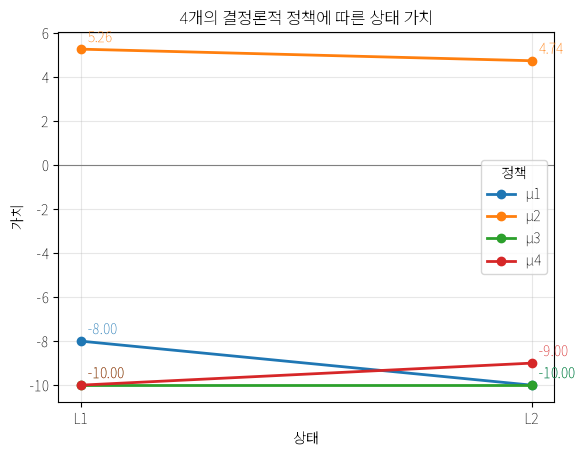

In [17]:
import matplotlib.pyplot as plt


plt.rcParams["font.family"] = "Noto Sans KR"
plt.rcParams["axes.unicode_minus"] = False


for name, state_values in results.items():
    line, = plt.plot(STATES, state_values, marker="o", linewidth=2, label=name)
    for state, value in zip(STATES, state_values):
        plt.annotate(f"{value:.2f}", (state, value),
                     xytext=(5, 5), textcoords="offset points",
                     color=line.get_color())

plt.title("4개의 결정론적 정책에 따른 상태 가치")
plt.xlabel("상태")
plt.ylabel("가치")
plt.axhline(0, color="gray", linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend(title="정책")
plt.show()


## 5. 결과 해석

계산 결과 $\mu_2$가 `L1`과 `L2` 모두에서 가장 높은 가치를 가집니다.

- `L1`에서는 `Right`를 선택해 보상 $+1$을 받습니다.
- `L2`에서는 `Left`를 선택해 다시 `L1`로 돌아갑니다.
- 두 상태를 왕복하면서 보상 $1,0,1,0,\ldots$을 반복해서 얻습니다.

따라서 이 환경의 최적 정책은 다음과 같습니다.

$$
\mu_*(L1)=\mathrm{Right},\qquad \mu_*(L2)=\mathrm{Left}
$$

